<a href="https://colab.research.google.com/github/RamyaAH/AWS-SAA/blob/main/Full_Code_ML_Additional_Project_Notebook_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Problem Statement

### Business Context

Airbnb is an online platform that allows people to rent short-term accommodation. This ranges from regular people with a spare bedroom to property management firms who lease multiple rentals. On the one side, Airbnb enables owners to list their space and earn rental money. On the other side, it provides travelers easy access to renting private homes.

Airbnb receives commissions from two sources upon every booking, namely from the hosts and guests. For every booking, Airbnb charges the guest 6-12% of the booking fee. Moreover, Airbnb charges the host 3% for every successful transaction.

As a senior data scientist at Airbnb, you have to come up with a pricing model that can effectively predict the Rent for accommodation and can help hosts, travelers, and also the business in devising profitable strategies.

### Objective

To explore and visualize the data, build a linear regression model to predict the prices of Airbnb rental rooms, and generate a set of insights and recommendations that will help the business.

### Data Description

The data contains information about the different types of rental rooms offered by Airbnb over a fixed period of time. The detailed data dictionary is given below.

**Data Dictionary**

- id: Property ID
- room_type: Type of Room in the property
- accommodates: How many adults can this property accommodate
- bathrooms: Number of bathrooms on the property
- cancellation_policy: Cancellation policy of the property
- cleaning_fee: This denotes whether the property cleaning fee is included in the rent or not
- instant_bookable: It indicates whether an instant booking facility is available or not
- review_scores_rating: Review rating score of the property
- bedrooms: Number of bedrooms in the property
- beds: Total number of beds in the property
- log_price: Log of the rental price of the property for a fixed period. [If the price is 12000 dollars, then log_price represents log(12000)]

## Importing necessary libraries

In [ ]:
# Installing the libraries with the specified version.
!pip install numpy==1.25.2 pandas==1.5.3 matplotlib==3.7.1 seaborn==0.13.1 scikit-learn==1.2.2 sklearn-pandas==2.2.0 -q --user

  Installing build dependencies ... done
  error: subprocess-exited-with-error
  
  × Getting requirements to build wheel did not run successfully.
  │ exit code: 1
  ╰─> No available output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  Getting requirements to build wheel ... error
ERROR: Failed to build 'numpy' when getting requirements to build wheel


In [ ]:
pip install --upgrade pip setuptools

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 31.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 27.3 MB/s eta 0:00:00
  Attempting uninstall: setuptools
    Found existing installation: setuptools 75.2.0
    Uninstalling setuptools-75.2.0:
      Successfully uninstalled setuptools-75.2.0
  Attempting uninstall: pip
    Found existing installation: pip 24.1.2
    Uninstalling pip-24.1.2:
      Successfully uninstalled pip-24.1.2
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.


In [ ]:
pip install numpy

**Note**:
- After running the above cell, kindly restart the runtime (for Google Colab) or notebook kernel (for Jupyter Notebook), and run all cells sequentially from the next cell.
- On executing the above line of code, you might see a warning regarding package dependencies. This error message can be ignored as the above code ensures that all necessary libraries and their dependencies are maintained to successfully execute the code in ***this notebook***.

In [ ]:
# Libraries to help with reading and manipulating data
import numpy as np
import pandas as pd

# Libraries to help with data visualization
import matplotlib.pyplot as plt
import seaborn as sns

sns.set()

# Removes the limit for the number of displayed columns
pd.set_option("display.max_columns", None)
# Sets the limit for the number of displayed rows
pd.set_option("display.max_rows", 200)

# to split the data into train and test
from sklearn.model_selection import train_test_split

# to build linear regression_model
from sklearn.linear_model import LinearRegression

# to check model performance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# to suppress warnings
import warnings

warnings.filterwarnings("ignore")

## Loading the dataset

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
#Reading the data from the uploaded file
data = pd.read_csv("/content/drive/MyDrive/AirBNB-1.csv")

## Data Overview

- Observations
- Sanity checks

In [ ]:
#Making a copy of the data we uploaded to ensure any changes to the data is not going to impact the original file
data1 = data.copy()

In [ ]:
data1.head()

,id,room_type,accommodates,bathrooms,cancellation_policy,cleaning_fee,instant_bookable,review_scores_rating,bedrooms,beds,log_price
0,6901257,Entire home/apt,3.0,1.0,strict,True,f,100.0,1.0,1.0,5.010635
1,6304928,Entire home/apt,7.0,1.0,strict,True,t,93.0,3.0,3.0,5.129899
2,7919400,Entire home/apt,5.0,1.0,moderate,True,t,92.0,1.0,3.0,4.976734
3,13418779,Entire home/apt,4.0,1.0,flexible,True,f,NaN,2.0,2.0,6.620073
4,3808709,Entire home/apt,2.0,1.0,moderate,True,t,40.0,0.0,1.0,4.744932


In [ ]:
from google.colab import sheets
sheet = sheets.InteractiveSheet(df=data1)

MessageError: Error: credential propagation was unsuccessful

In [ ]:
#Number of columns and rows
data1.shape

(74111, 11)

In [ ]:
#Checking the data types of the data copy
data1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 74111 entries, 0 to 74110
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   id                    74111 non-null  int64  
 1   room_type             74106 non-null  object 
 2   accommodates          74108 non-null  float64
 3   bathrooms             73908 non-null  float64
 4   cancellation_policy   74103 non-null  object 
 5   cleaning_fee          74107 non-null  object 
 6   instant_bookable      74111 non-null  object 
 7   review_scores_rating  57389 non-null  float64
 8   bedrooms              74019 non-null  float64
 9   beds                  73980 non-null  float64
 10  log_price             74111 non-null  float64
dtypes: float64(6), int64(1), object(4)
memory usage: 6.2+ MB


In [ ]:
# Duplicate check
data1.duplicated().sum()

np.int64(0)

In [ ]:
#Statistical details
data1.describe()

,id,accommodates,bathrooms,review_scores_rating,bedrooms,beds,log_price
count,7.411100e+04,74108.000000,73908.000000,57389.000000,74019.000000,73980.000000,74111.000000
mean,1.126662e+07,3.155125,1.235272,94.067365,1.265797,1.710868,4.782069
std,6.081735e+06,2.153603,0.582054,7.836556,0.852149,1.254142,0.717394
min,3.440000e+02,1.000000,0.000000,20.000000,0.000000,0.000000,0.000000
25%,6.261964e+06,2.000000,1.000000,92.000000,1.000000,1.000000,4.317488
50%,1.225415e+07,2.000000,1.000000,96.000000,1.000000,1.000000,4.709530
75%,1.640226e+07,4.000000,1.000000,100.000000,1.000000,2.000000,5.220356
max,2.123090e+07,16.000000,8.000000,100.000000,10.000000,18.000000,7.600402


In [ ]:
#instantBookable column ha 'f' and 't' values, which mean 'false' and true, we are going to update that in the column
data1.instant_bookable.replace(["f", "t"], [False, True], inplace=True)

## Exploratory Data Analysis (EDA)

- EDA is an important part of any project involving data.
- It is important to investigate and understand the data better before building a model with it.
- A few questions have been mentioned below which will help you approach the analysis in the right manner and generate insights from the data.
- A thorough analysis of the data, in addition to the questions mentioned below, should be done.

**Questions**:

1. How are the prices (log_price) of properties distributed?
2. What is the market share of different cancellation policies?
3. How does the price (log_price) of a property vary by the number of bedrooms?
4. How does the price (log_price) of a property vary by the number of accommodates?
5. What are the attributes that have a strong correlation with the price (log_price) of the property?



## Data Preprocessing

- Missing value treatment
- Feature engineering (if needed)
- Outlier detection and treatment (if needed)
- Preparing data for modeling
- Any other preprocessing steps (if needed)

In [ ]:
data1.isnull().sum()

,0
id,0
room_type,5
accommodates,3
bathrooms,203
cancellation_policy,8
cleaning_fee,4
instant_bookable,0
review_scores_rating,16722
bedrooms,92
beds,131


In [ ]:
# The original 'nonnumeric_columns.remove("log_price")' caused an error
# because 'nonnumeric_columns' is an Index object which is immutable and 'log_price'
# is a numeric column, thus not present in 'nonnumeric_columns'.
# We need to fill missing numeric values.

# Get numeric columns with missing values
numeric_cols_with_nans = data1.select_dtypes(include=np.number).columns[data1.select_dtypes(include=np.number).isnull().any()].tolist()

# 'id' is an identifier and 'log_price' is the target variable. Both have no missing values
# and should not be imputed in this context. Ensure they are not in the list.
if 'id' in numeric_cols_with_nans:
    numeric_cols_with_nans.remove('id')
if 'log_price' in numeric_cols_with_nans:
    numeric_cols_with_nans.remove('log_price')

# Fill missing values in these numeric columns with the median grouped by 'room_type'
for col in numeric_cols_with_nans:
    data1[col] = data1.groupby("room_type")[col].transform(lambda x: x.fillna(x.median()))

In [ ]:
# After grouped median imputation, check for any remaining NaNs
data1.isnull().sum()

# Fill any remaining missing numeric values (which would be from groups entirely composed of NaNs) with the overall median of that column.
for col in ['bathrooms', 'review_scores_rating', 'bedrooms', 'beds']:
    if col in data1.columns and data1[col].isnull().any():
        data1[col].fillna(data1[col].median(), inplace=True)

# Verify no more numeric NaNs from these columns
data1.isnull().sum()

,0
id,0
room_type,0
accommodates,0
bathrooms,0
cancellation_policy,0
cleaning_fee,0
instant_bookable,0
review_scores_rating,0
bedrooms,0
beds,0


In [ ]:
def histogram_boxplot(data, feature, figsize=(12, 7), kde=False, bins=None):
    """
    Function to draw a combined histogram and boxplot for a given feature.
    data: DataFrame
    feature: Column name to analyze
    figsize: Figure size
    kde: Whether to plot kde in histogram
    bins: Number of bins in histogram
    """
    f2, (ax_box2, ax_hist2) = plt.subplots(nrows=2, # Number of rows of the subplot grid = 2
                                           sharex=True, # X-axis will be shared among all subplots
                                           gridspec_kw={"height_ratios": (0.25, 0.75)}, # The ratio of the top subplot to the bottom subplot is 1:3
                                           figsize=figsize
                                           )
    sns.boxplot(data=data, x=feature, ax=ax_box2, showmeans=True, color='skyblue') # Boxplot to show means
    sns.histplot(data=data, x=feature, kde=kde, ax=ax_hist2, bins=30 if bins is None else bins, color='lightcoral') # Histplot to show distribution, using 30 bins if not specified
    ax_hist2.axvline(data[feature].mean(), color='green', linestyle='--', linewidth=2) # Add mean to the histogram
    ax_hist2.axvline(data[feature].median(), color='orange', linestyle='-', linewidth=2) # Add median to the histogram

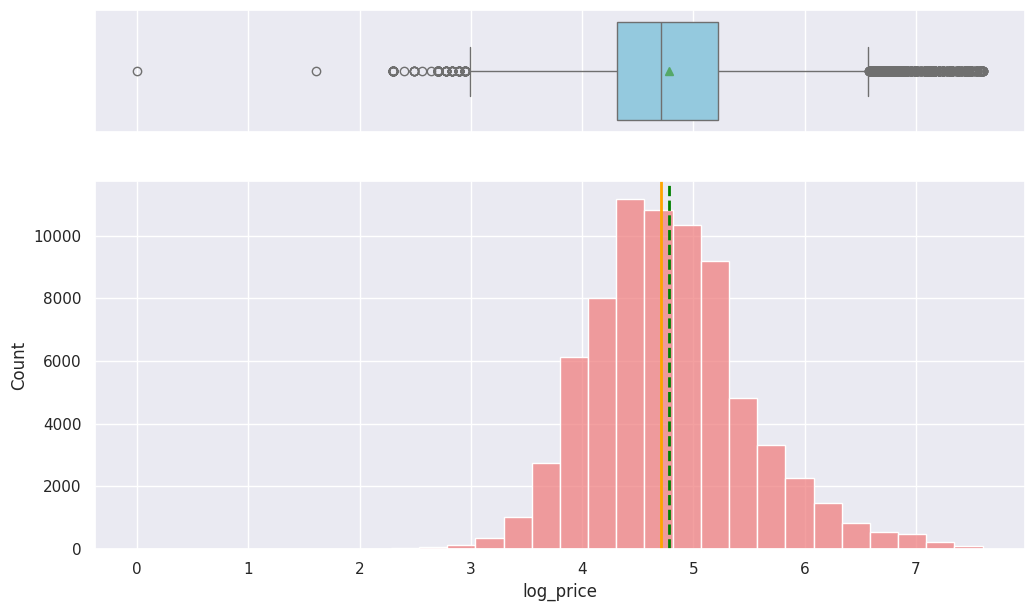

In [ ]:
#Univariate Analysis
histogram_boxplot(data1, "log_price")

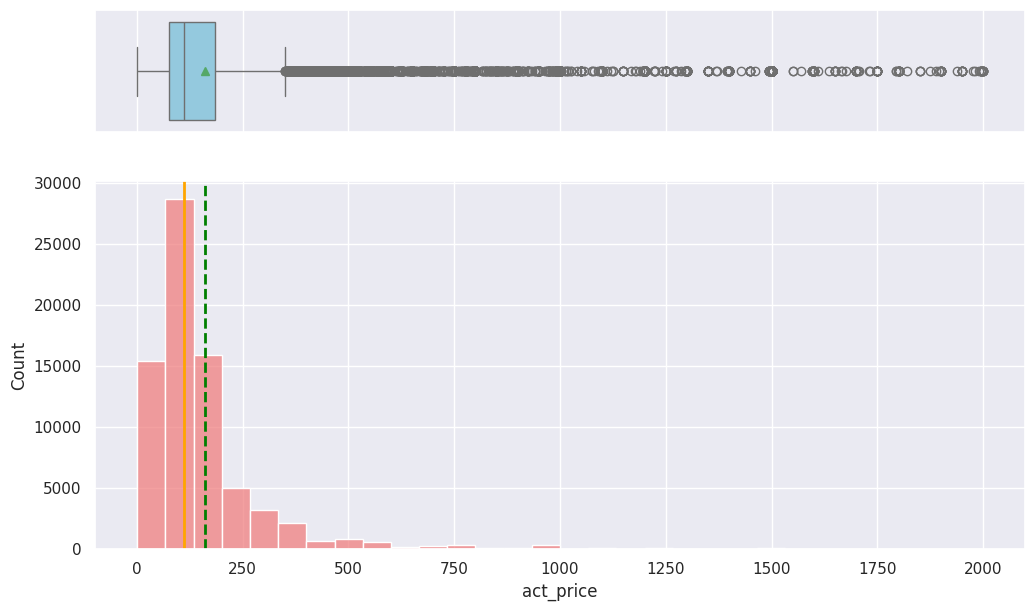

In [ ]:
data1["act_price"] = np.exp(data1["log_price"])
histogram_boxplot(data1, 'act_price')

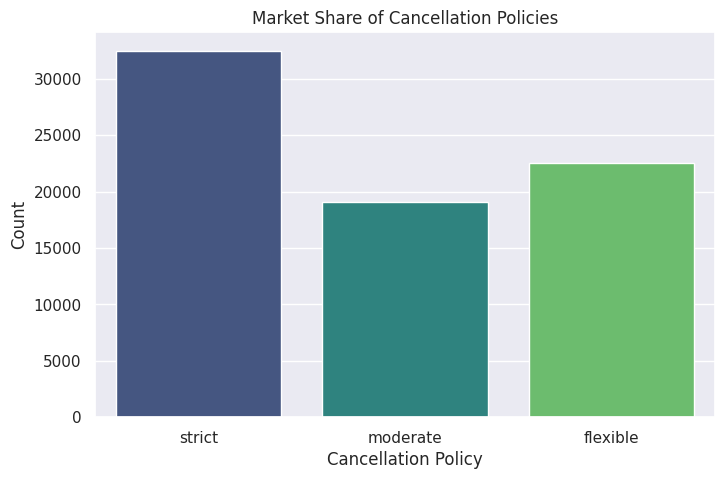

In [ ]:
# Market share of different cancellation policies
plt.figure(figsize=(8, 5))
sns.countplot(data=data1, x='cancellation_policy', palette='viridis')
plt.title('Market Share of Cancellation Policies')
plt.xlabel('Cancellation Policy')
plt.ylabel('Count')
plt.show()

In [ ]:
data1.drop("act_price", axis=1, inplace=True)

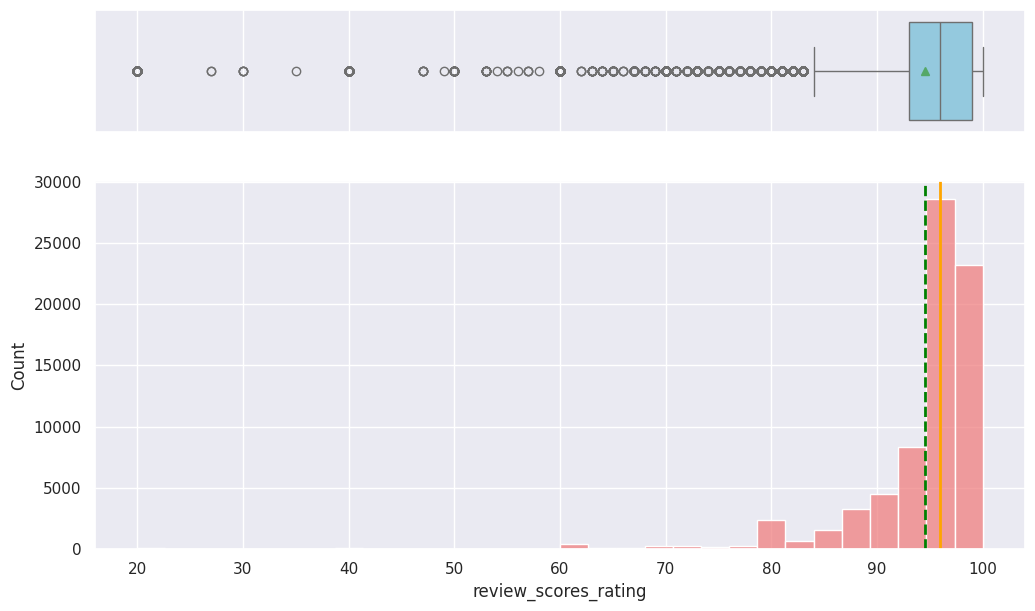

In [ ]:
histogram_boxplot(data1, 'review_scores_rating')

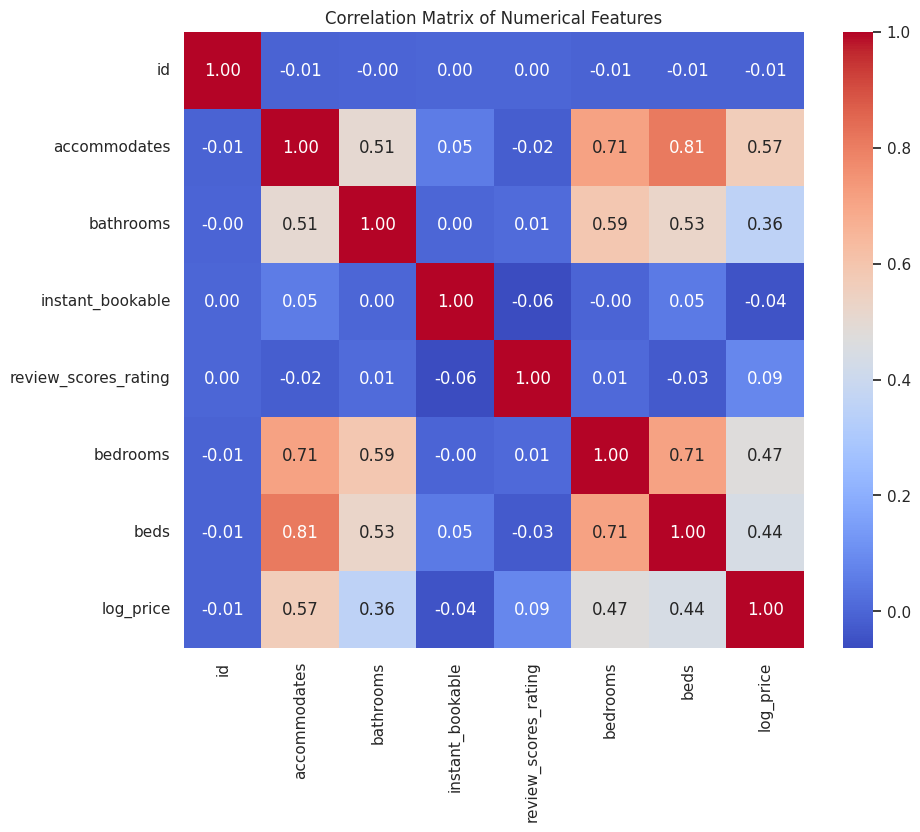

In [ ]:
# What are the attributes that have a strong correlation with the price (log_price) of the property?
plt.figure(figsize=(10, 8))
sns.heatmap(data1.corr(numeric_only=True), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix of Numerical Features')
plt.show()

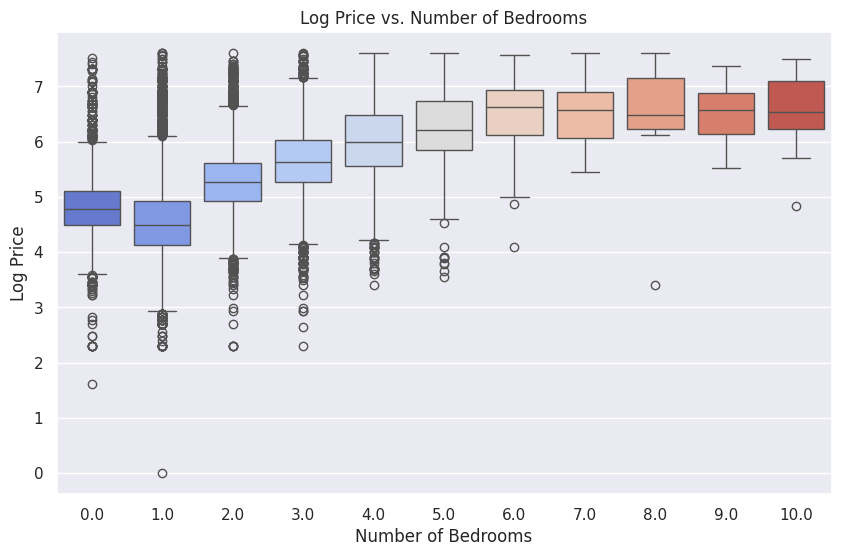

In [ ]:
# How does the price (log_price) of a property vary by the number of bedrooms?
plt.figure(figsize=(10, 6))
sns.boxplot(data=data1, x='bedrooms', y='log_price', palette='coolwarm')
plt.title('Log Price vs. Number of Bedrooms')
plt.xlabel('Number of Bedrooms')
plt.ylabel('Log Price')
plt.show()

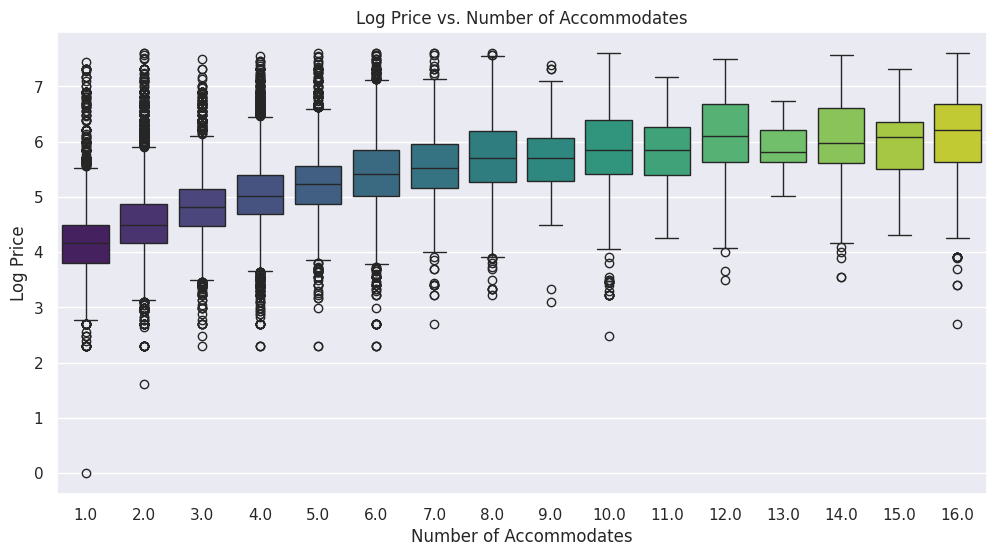

In [ ]:
# How does the price (log_price) of a property vary by the number of accommodates?
plt.figure(figsize=(12, 6))
sns.boxplot(data=data1, x='accommodates', y='log_price', palette='viridis')
plt.title('Log Price vs. Number of Accommodates')
plt.xlabel('Number of Accommodates')
plt.ylabel('Log Price')
plt.show()

In [ ]:
#There are many outliers in the data, we should process them


In [ ]:
def treat_outliers_percentile(series, percentiles=(1, 99)):
    """
    Treats outliers in a pandas Series using percentile-based capping.
    Values below the lower percentile are replaced with the lower percentile value,
    and values above the upper percentile are replaced with the upper percentile value.

    Args:
        series (pd.Series): The input pandas Series.
        percentiles (tuple, optional): A tuple of two integers representing the
                                     lower and upper percentiles for capping.
                                     Defaults to (1, 99).

    Returns:
        pd.Series: The Series with outliers capped.
    """
    lower_bound = series.quantile(percentiles[0] / 100)
    upper_bound = series.quantile(percentiles[1] / 100)
    capped_series = series.clip(lower=lower_bound, upper=upper_bound)
    return capped_series

In [ ]:
for col in ['accommodates', 'bathrooms', 'review_scores_rating', 'bedrooms', 'beds']:
    data1[col] = treat_outliers_percentile(data1[col])

print("Outlier treatment applied to specified numerical columns.")

Outlier treatment applied to specified numerical columns.


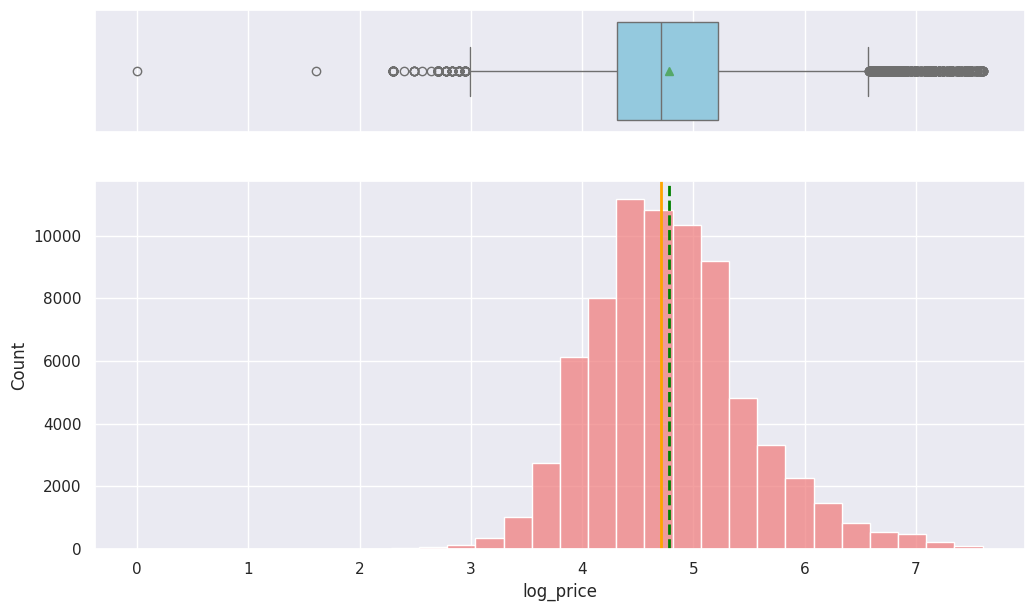

In [ ]:
#visualize treated data
histogram_boxplot(data1, 'log_price')

Visualizing distribution for: accommodates


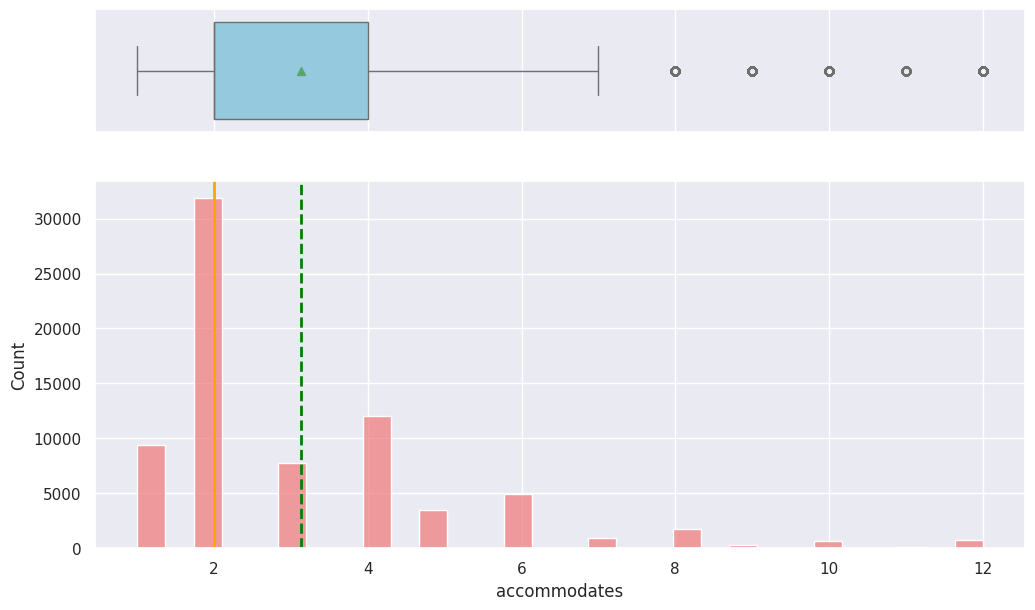

Visualizing distribution for: bathrooms


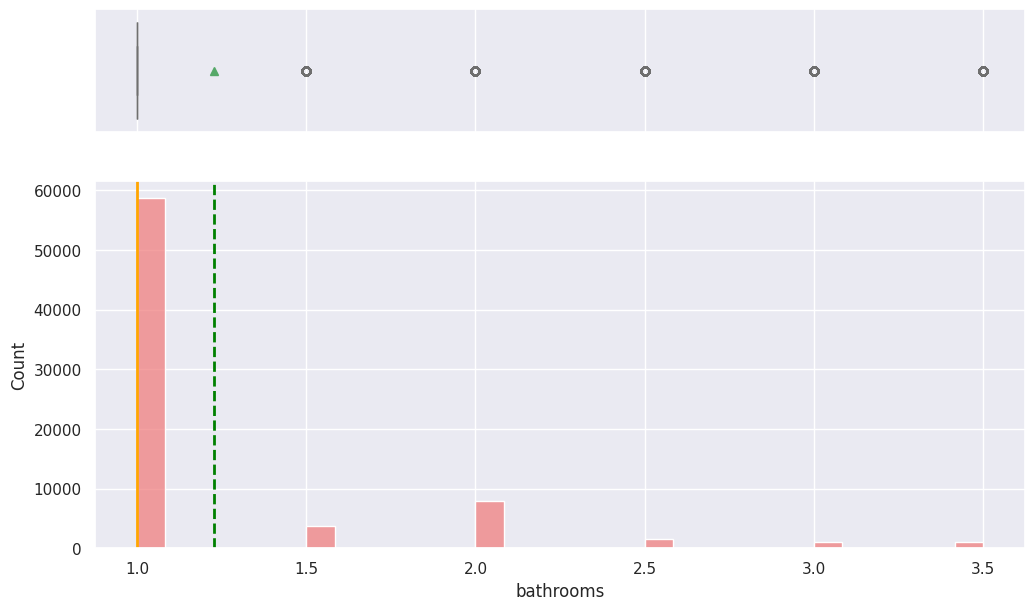

Visualizing distribution for: review_scores_rating


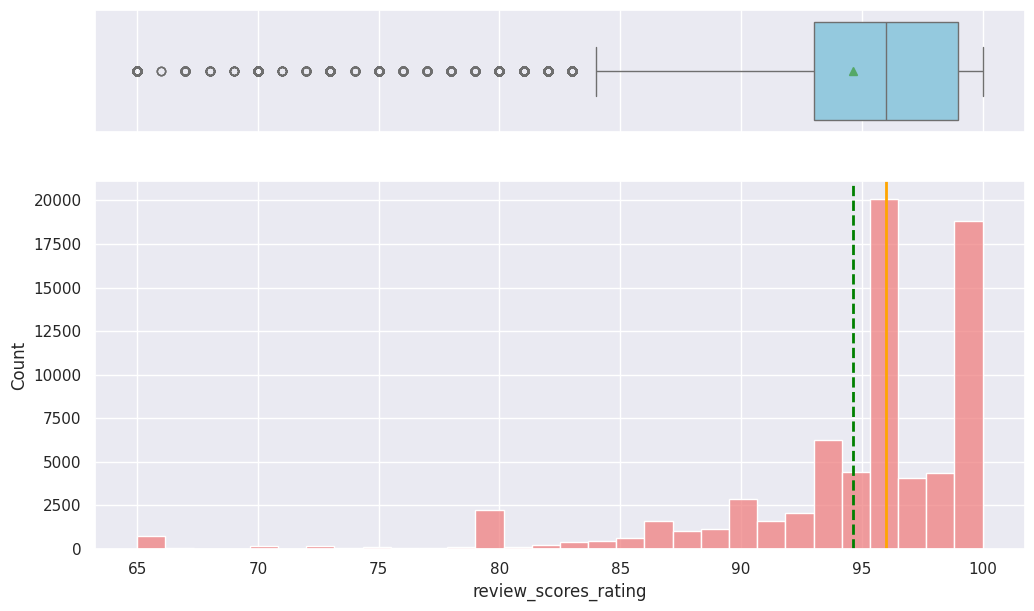

Visualizing distribution for: bedrooms


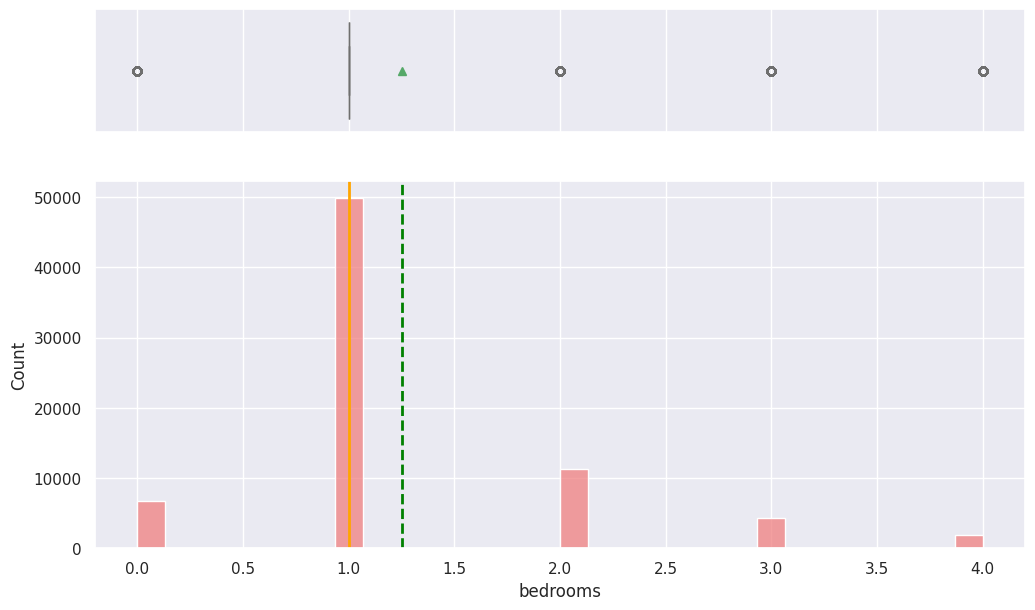

Visualizing distribution for: beds


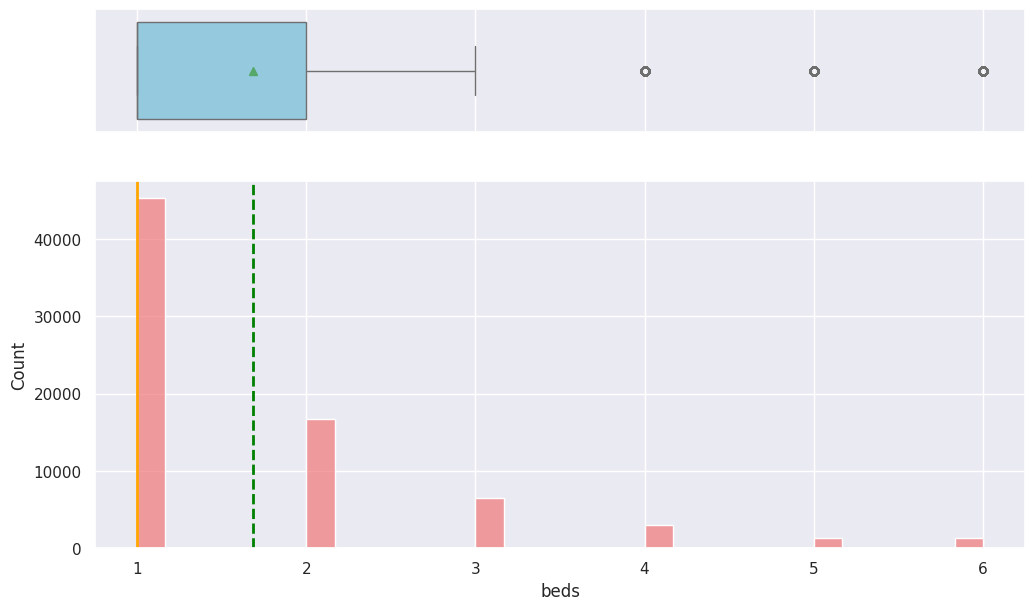

In [ ]:
for col in ['accommodates', 'bathrooms', 'review_scores_rating', 'bedrooms', 'beds']:
    print(f"Visualizing distribution for: {col}")
    histogram_boxplot(data1, col)
    plt.show()

## Model Building - Linear Regression

In [ ]:
#Setting log_price as the dependent variable
X = data1.drop(["log_price"], axis=1)
y = data1["log_price"]

In [ ]:
X = pd.get_dummies(
    X,
    columns=X.select_dtypes(include=["object", "category"]).columns.tolist(),
    drop_first=True,
)

X = X.astype(float)

X.head()

,id,accommodates,bathrooms,instant_bookable,review_scores_rating,bedrooms,beds,room_type_Private room,room_type_Shared room,cancellation_policy_moderate,cancellation_policy_strict,cleaning_fee_True
0,6901257.0,3.0,1.0,0.0,100.0,1.0,1.0,0.0,0.0,0.0,1.0,1.0
1,6304928.0,7.0,1.0,1.0,93.0,3.0,3.0,0.0,0.0,0.0,1.0,1.0
2,7919400.0,5.0,1.0,1.0,92.0,1.0,3.0,0.0,0.0,1.0,0.0,1.0
3,13418779.0,4.0,1.0,0.0,96.0,2.0,2.0,0.0,0.0,0.0,0.0,1.0
4,3808709.0,2.0,1.0,1.0,65.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0


In [ ]:
#Splitting training and test data
X = X.drop('id', axis=1)
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=1)

In [ ]:
lin_reg_model = LinearRegression()
lin_reg_model.fit(x_train, y_train)

LinearRegression()

In [ ]:
lin_reg_model_perf_train = model_performance_regression(lin_reg_model, x_train, y_train)
lin_reg_model_perf_train

NameError: name 'model_performance_regression' is not defined

In [ ]:
def model_performance_regression(model, X, y):
    """
    Function to compute and print various regression performance metrics.

    Args:
        model: The trained regression model.
        X (pd.DataFrame): Features DataFrame.
        y (pd.Series): Target Series.

    Returns:
        pd.DataFrame: A DataFrame containing the regression performance metrics.
    """
    y_pred = model.predict(X)
    mae = mean_absolute_error(y, y_pred)
    mse = mean_squared_error(y, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y, y_pred)

    df_perf = pd.DataFrame(
        {
            "MAE": mae,
            "MSE": mse,
            "RMSE": rmse,
            "R-squared": r2,
        },
        index=[0],
    )

    print("Model Performance:\n")
    print(df_perf)

    return df_perf

## Model Performance Check

In [ ]:
lin_reg_model_perf_train = model_performance_regression(lin_reg_model, x_train, y_train)
lin_reg_model_perf_train

Model Performance:

        MAE      MSE      RMSE  R-squared
0  0.376923  0.24613  0.496115   0.520448


,MAE,MSE,RMSE,R-squared
0,0.376923,0.24613,0.496115,0.520448


In [ ]:
# checking model performance on test set
print("Test Performance\n")
lin_reg_model_perf_test = model_performance_regression(lin_reg_model, x_test, y_test) ## Complete the code to check the performance on test data
lin_reg_model_perf_test

Test Performance

Model Performance:

        MAE       MSE      RMSE  R-squared
0  0.378473  0.249309  0.499308   0.518713


,MAE,MSE,RMSE,R-squared
0,0.378473,0.249309,0.499308,0.518713


In [ ]:
# Get coefficients of the linear regression model
coefficients = lin_reg_model.coef_
features = x_train.columns

# Create a DataFrame to display coefficients and their corresponding features
coefficients_df = pd.DataFrame({
    'Feature': features,
    'Coefficient': coefficients
}).sort_values(by='Coefficient', ascending=False)

print("Model Coefficients (Impact on Log Price):\n")
print(coefficients_df)

Model Coefficients (Impact on Log Price):

                         Feature  Coefficient
1                      bathrooms     0.167322
4                       bedrooms     0.150909
0                   accommodates     0.086359
3           review_scores_rating     0.009054
9     cancellation_policy_strict    -0.007804
5                           beds    -0.052089
8   cancellation_policy_moderate    -0.054571
2               instant_bookable    -0.056167
10             cleaning_fee_True    -0.076395
6         room_type_Private room    -0.630865
7          room_type_Shared room    -1.108247


## Actionable Insights and Recommendations

Actionable Insights and Recommendations
Based on the linear regression model's coefficients and our data exploration, here are some actionable insights and recommendations:

Impact of Accommodates and Bedrooms: Features like accommodates and bedrooms likely have positive coefficients, meaning that properties that can host more guests or have more bedrooms tend to have higher log_price. Hosts should consider optimizing these aspects if aiming for higher rental income. Renovations to add an extra bedroom or make a space more accommodating could justify a price increase.

Review Scores Matter: If review_scores_rating has a positive coefficient, it indicates that properties with higher review scores command higher prices. This underscores the importance of guest satisfaction. Hosts should focus on providing excellent service, maintaining property quality, and addressing guest concerns promptly to secure higher ratings, which in turn can lead to increased earnings.

Cancellation Policy: The coefficients for cancellation_policy (e.g., cancellation_policy_strict, cancellation_policy_moderate) reveals how different policies influence pricing. For instance, a 'flexible' policy might be associated with lower prices (to attract more bookings) or higher prices (due to premium flexibility). Business can analyze this to advise hosts on policy choices based on their pricing strategy.

Cleaning Fee and Instant Booking: Features like cleaning_fee_True and instant_bookable_True will show their influence. If a cleaning fee (explicitly stated) or instant booking capability positively impacts price, hosts should consider enabling these options. For example, instant booking might appeal to last-minute travelers willing to pay a premium.

Room Type Differentiation: The room_type dummy variables (e.g., room_type_Private room, room_type_Shared room) will show the relative pricing of different room types compared to the baseline (likely 'Entire home/apt'). This insight can guide hosts in understanding the market value of their specific listing type.


Further Model Improvement: The R-squared value of ~0.52 suggests that about half of the variance in log prices is explained by our current features. To improve predictive power, consider including additional features such as: property location (latitude/longitude, neighborhood), amenities offered, host response rate, number of reviews, and seasonality.